In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score,
    matthews_corrcoef,
    cohen_kappa_score,
    log_loss,
    roc_curve,
    auc,
    precision_recall_curve
)

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [2]:
data = pd.read_csv("heart.csv")
data.head(10)

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
5,39,M,NAP,120,339,0,Normal,170,N,0.0,Up,0
6,45,F,ATA,130,237,0,Normal,170,N,0.0,Up,0
7,54,M,ATA,110,208,0,Normal,142,N,0.0,Up,0
8,37,M,ASY,140,207,0,Normal,130,Y,1.5,Flat,1
9,48,F,ATA,120,284,0,Normal,120,N,0.0,Up,0


## First Model

In [3]:
sex_mapping = {
    "M":0,
    "F":1
}

exAng_mapping = {
    "N":0,
    "Y":1
}

data["Sex"] = data["Sex"].map(sex_mapping)
data["ExerciseAngina"] = data["ExerciseAngina"].map(exAng_mapping)

data = pd.get_dummies(data, columns=["ChestPainType", "RestingECG", "ST_Slope"])

data = data.drop("ChestPainType_TA", axis = 1)
data = data.drop("RestingECG_Normal", axis = 1)
data = data.drop("ST_Slope_Up", axis = 1)

data.head(10)

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,HeartDisease,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,RestingECG_LVH,RestingECG_ST,ST_Slope_Down,ST_Slope_Flat
0,40,0,140,289,0,172,0,0.0,0,False,True,False,False,False,False,False
1,49,1,160,180,0,156,0,1.0,1,False,False,True,False,False,False,True
2,37,0,130,283,0,98,0,0.0,0,False,True,False,False,True,False,False
3,48,1,138,214,0,108,1,1.5,1,True,False,False,False,False,False,True
4,54,0,150,195,0,122,0,0.0,0,False,False,True,False,False,False,False
5,39,0,120,339,0,170,0,0.0,0,False,False,True,False,False,False,False
6,45,1,130,237,0,170,0,0.0,0,False,True,False,False,False,False,False
7,54,0,110,208,0,142,0,0.0,0,False,True,False,False,False,False,False
8,37,0,140,207,0,130,1,1.5,1,True,False,False,False,False,False,True
9,48,1,120,284,0,120,0,0.0,0,False,True,False,False,False,False,False


In [4]:
X = data.drop("HeartDisease", axis=1)
y = data["HeartDisease"]

X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size = 0.2,
    stratify = y,
    random_state = 1923
)

In [5]:
clf = RandomForestClassifier(n_estimators=100, random_state = 1923)
clf.fit(X_train, y_train)

RandomForestClassifier(random_state=1923)

In [6]:
y_pred = clf.predict(X_test)
y_prob = clf.predict_proba(X_test)[:, 1]

In [7]:
def classification_metrics(y_true, y_pred, y_prob=None):
 
    # -------------------------
    # Confusion Matrix
    # -------------------------
    cm = confusion_matrix(y_true, y_pred)

    print("=" * 60)
    print("CONFUSION MATRIX")
    print("=" * 60)
    print(cm)

    # Binary classification için
    if cm.shape == (2, 2):

        tn, fp, fn, tp = cm.ravel()

        sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
        npv = tn / (tn + fn) if (tn + fn) > 0 else 0
        ppv = tp / (tp + fp) if (tp + fp) > 0 else 0

    else:
        sensitivity = np.nan
        specificity = np.nan
        npv = np.nan
        ppv = np.nan

    # -------------------------
    # Basic Metrics
    # -------------------------
    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    # -------------------------
    # MCC
    # -------------------------
    mcc = matthews_corrcoef(y_true, y_pred)

    # -------------------------
    # Cohen's Kappa
    # -------------------------
    kappa = cohen_kappa_score(y_true, y_pred)

    # -------------------------
    # ROC-AUC / PR-AUC / LogLoss
    # -------------------------
    if y_prob is not None:

        # Binary
        if len(np.unique(y_true)) == 2:

            roc_auc = roc_auc_score(y_true, y_prob)

            pr_auc = average_precision_score(
                y_true,
                y_prob
            )

            logloss = log_loss(
                y_true,
                y_prob
            )

        # Multiclass
        else:

            roc_auc = roc_auc_score(
                y_true,
                y_prob,
                multi_class="ovr",
                average="weighted"
            )

            pr_auc = np.nan

            logloss = log_loss(
                y_true,
                y_prob
            )

    else:
        roc_auc = np.nan
        pr_auc = np.nan
        logloss = np.nan

    # -------------------------
    # Results
    # -------------------------
    results = {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall / Sensitivity": recall,
        "Specificity": specificity,
        "F1 Score": f1,
        "PPV": ppv,
        "NPV": npv,
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc,
        "MCC": mcc,
        "Cohen Kappa": kappa,
        "Log Loss": logloss
    }

    results_df = pd.DataFrame(
        results.items(),
        columns=["Metric", "Score"]
    )

    print("\n" + "=" * 60)
    print("CLASSIFICATION METRICS")
    print("=" * 60)

    print(
        results_df.to_string(
            index=False,
            float_format=lambda x: f"{x:.4f}"
        )
    )

    # -------------------------
    # Classification Report
    # -------------------------
    print("\n" + "=" * 60)
    print("CLASSIFICATION REPORT")
    print("=" * 60)

    print(
        classification_report(
            y_true,
            y_pred,
            zero_division=0
        )
    )

    return results_df, cm

In [8]:
results, cm = classification_metrics(
    y_test,
    y_pred,
    y_prob
)

CONFUSION MATRIX
[[71 11]
 [11 91]]

CLASSIFICATION METRICS
              Metric  Score
            Accuracy 0.8804
           Precision 0.8804
Recall / Sensitivity 0.8804
         Specificity 0.8659
            F1 Score 0.8804
                 PPV 0.8922
                 NPV 0.8659
             ROC-AUC 0.9336
              PR-AUC 0.9395
                 MCC 0.7580
         Cohen Kappa 0.7580
            Log Loss 0.3220

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.87      0.87      0.87        82
           1       0.89      0.89      0.89       102

    accuracy                           0.88       184
   macro avg       0.88      0.88      0.88       184
weighted avg       0.88      0.88      0.88       184



# Second Model with Some Improvements

In [9]:
data.describe()

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,0.210240,132.396514,198.799564,0.233115,136.809368,0.404139,0.887364,0.553377
std,9.432617,0.407701,18.514154,109.384145,0.423046,25.460334,0.490992,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,0.000000,60.000000,0.000000,-2.600000,0.000000
25%,47.000000,0.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000,0.000000
50%,54.000000,0.000000,130.000000,223.000000,0.000000,138.000000,0.000000,0.600000,1.000000
75%,60.000000,0.000000,140.000000,267.000000,0.000000,156.000000,1.000000,1.500000,1.000000
max,77.000000,1.000000,200.000000,603.000000,1.000000,202.000000,1.000000,6.200000,1.000000


In [10]:
chest_pain_cols = [col for col in data.columns if 'ChestPainType' in col]
st_slope_cols = [col for col in data.columns if 'ST_Slope' in col]

for cp in chest_pain_cols:
    for st in st_slope_cols:
        interaction_name = f"{cp}_x_{st}"
        
        data[interaction_name] = data[cp] * data[st]

print(data[[col for col in data.columns if '_x_' in col]].head())

   ChestPainType_ASY_x_ST_Slope_Down  ChestPainType_ASY_x_ST_Slope_Flat  \
0                              False                              False   
1                              False                              False   
2                              False                              False   
3                              False                               True   
4                              False                              False   

   ChestPainType_ATA_x_ST_Slope_Down  ChestPainType_ATA_x_ST_Slope_Flat  \
0                              False                              False   
1                              False                              False   
2                              False                              False   
3                              False                              False   
4                              False                              False   

   ChestPainType_NAP_x_ST_Slope_Down  ChestPainType_NAP_x_ST_Slope_Flat  
0                       

In [11]:
data[data["Cholesterol"] == 0]

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,HeartDisease,ChestPainType_ASY,...,RestingECG_LVH,RestingECG_ST,ST_Slope_Down,ST_Slope_Flat,ChestPainType_ASY_x_ST_Slope_Down,ChestPainType_ASY_x_ST_Slope_Flat,ChestPainType_ATA_x_ST_Slope_Down,ChestPainType_ATA_x_ST_Slope_Flat,ChestPainType_NAP_x_ST_Slope_Down,ChestPainType_NAP_x_ST_Slope_Flat
293,65,0,115,0,0,93,1,0.0,1,True,...,False,False,False,True,False,True,False,False,False,False
294,32,0,95,0,1,127,0,0.7,1,False,...,False,False,False,False,False,False,False,False,False,False
295,61,0,105,0,1,110,1,1.5,1,True,...,False,False,False,False,False,False,False,False,False,False
296,50,0,145,0,1,139,1,0.7,1,True,...,False,False,False,True,False,True,False,False,False,False
297,57,0,110,0,1,131,1,1.4,1,True,...,False,True,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
514,43,0,122,0,0,120,0,0.5,1,True,...,False,False,False,False,False,False,False,False,False,False
515,63,0,130,0,1,160,0,3.0,0,False,...,False,True,False,True,False,False,False,False,False,True
518,48,0,102,0,1,110,1,1.0,1,False,...,False,True,True,False,False,False,False,False,True,False
535,56,0,130,0,0,122,1,1.0,1,True,...,True,False,False,True,False,True,False,False,False,False


In [12]:
data['RestingBP'] = data['RestingBP'].replace(0, np.nan)
data['Cholesterol'] = data['Cholesterol'].replace(0, np.nan)

X = data.drop('HeartDisease', axis=1)
y = data['HeartDisease']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

imputer = IterativeImputer(max_iter=10, random_state=1923)
imputer.fit(X_train)

X_train_imputed = imputer.transform(X_train)
X_test_imputed = imputer.transform(X_test)

X_train = pd.DataFrame(X_train_imputed, columns=X_train.columns, index=X_train.index)
X_test = pd.DataFrame(X_test_imputed, columns=X_test.columns, index=X_test.index)

In [13]:
clf = RandomForestClassifier(n_estimators=100, random_state = 1923)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
y_prob = clf.predict_proba(X_test)[:, 1]

In [14]:
results, cm = classification_metrics(
    y_test,
    y_pred,
    y_prob
)

CONFUSION MATRIX
[[73  9]
 [ 9 93]]

CLASSIFICATION METRICS
              Metric  Score
            Accuracy 0.9022
           Precision 0.9022
Recall / Sensitivity 0.9022
         Specificity 0.8902
            F1 Score 0.9022
                 PPV 0.9118
                 NPV 0.8902
             ROC-AUC 0.9383
              PR-AUC 0.9385
                 MCC 0.8020
         Cohen Kappa 0.8020
            Log Loss 0.3274

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.89      0.89      0.89        82
           1       0.91      0.91      0.91       102

    accuracy                           0.90       184
   macro avg       0.90      0.90      0.90       184
weighted avg       0.90      0.90      0.90       184



# Third Model with Best Threshold Value

In [15]:
y_probs = clf.predict_proba(X_test)[:, 1]
threshold = 0.35

y_pred_custom = (y_probs >= threshold).astype(int)

print(f"============================================================")
print(f"THRESHOLD: {threshold}")
print(f"============================================================")
print("\nCONFUSION MATRIX:")
print(confusion_matrix(y_test, y_pred_custom))

print("\nCLASSIFICATION REPORT:")
print(classification_report(y_test, y_pred_custom))

print("\nCLASSIFICATION METRICS:")
print(classification_metrics(y_test, y_pred_custom))

THRESHOLD: 0.35

CONFUSION MATRIX:
[[62 20]
 [ 4 98]]

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

           0       0.94      0.76      0.84        82
           1       0.83      0.96      0.89       102

    accuracy                           0.87       184
   macro avg       0.88      0.86      0.86       184
weighted avg       0.88      0.87      0.87       184


CLASSIFICATION METRICS:
CONFUSION MATRIX
[[62 20]
 [ 4 98]]

CLASSIFICATION METRICS
              Metric  Score
            Accuracy 0.8696
           Precision 0.8790
Recall / Sensitivity 0.8696
         Specificity 0.7561
            F1 Score 0.8673
                 PPV 0.8305
                 NPV 0.9394
             ROC-AUC    NaN
              PR-AUC    NaN
                 MCC 0.7429
         Cohen Kappa 0.7309
            Log Loss    NaN

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.94      0.76      0.84        82
           1  

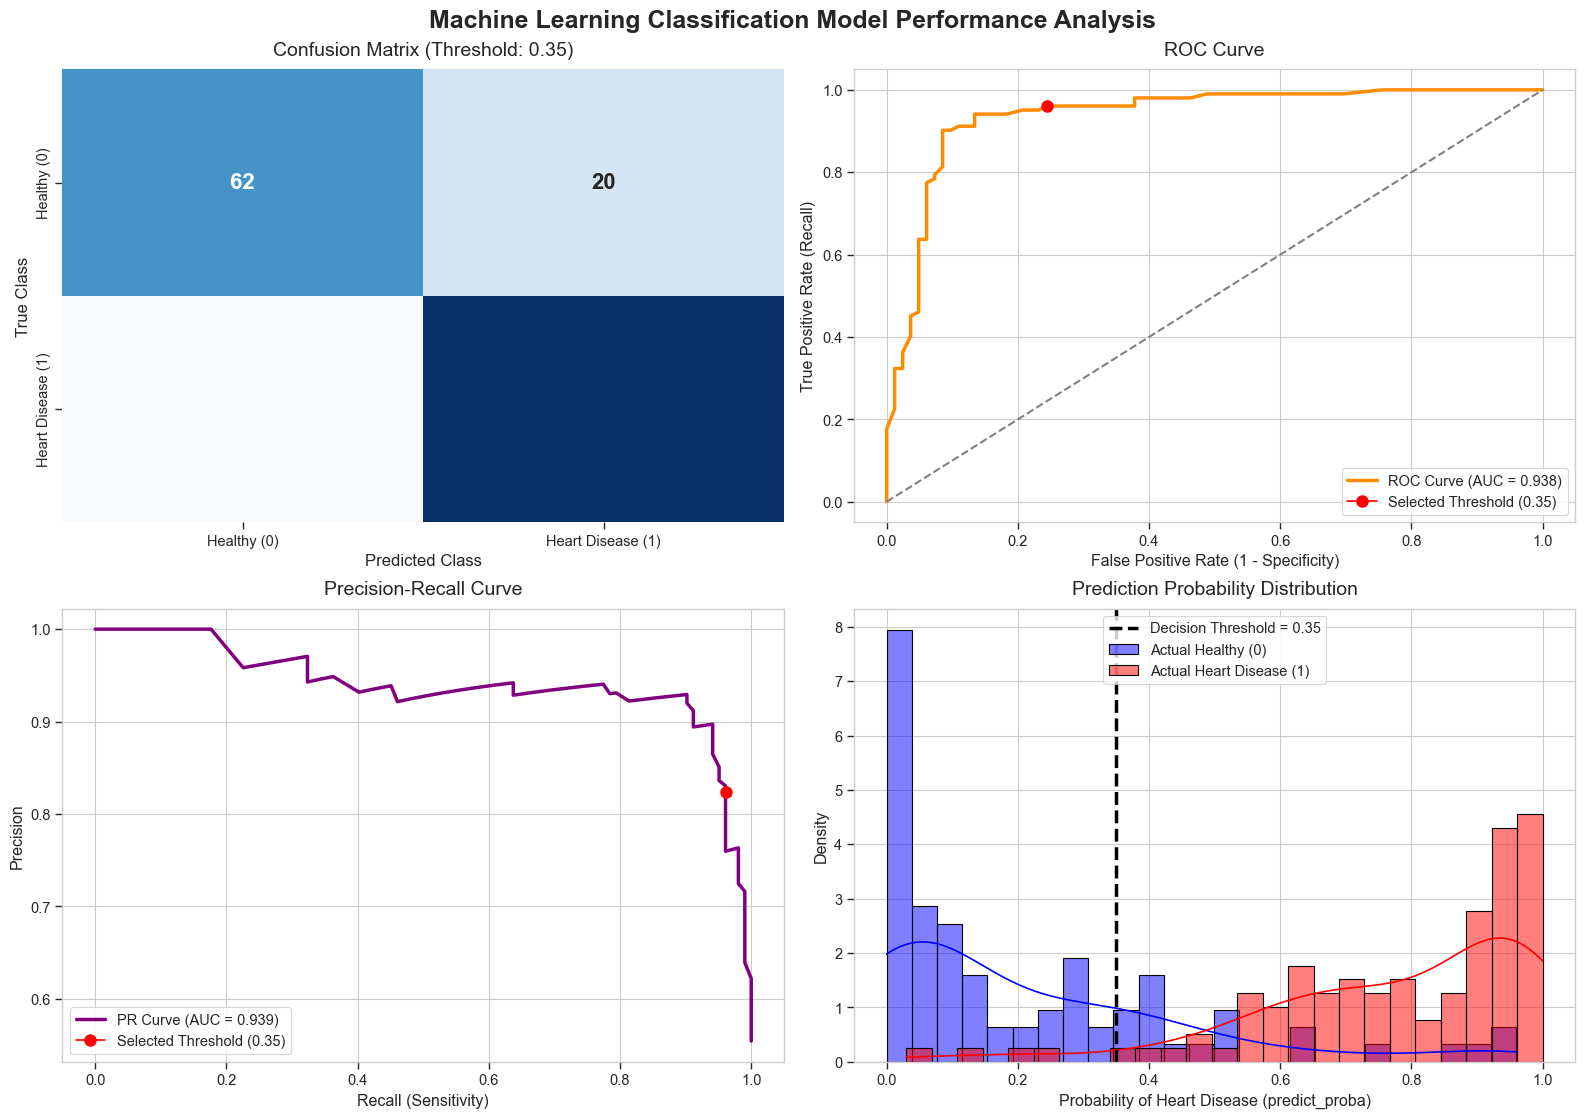

In [16]:
# Style settings for professional look
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_context("paper", font_scale=1.2)

# Variables needed from previous steps:
# y_test: True labels from the test set
# y_probs: Probabilities from model.predict_proba(X_test)[:, 1]
# threshold = 0.35
# y_pred_custom = (y_probs >= threshold).astype(int)

threshold = 0.35

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Machine Learning Classification Model Performance Analysis', fontsize=18, fontweight='bold', y=0.93)

# ---------------------------------------------------------
# 1. CONFUSION MATRIX
# ---------------------------------------------------------
cm = confusion_matrix(y_test, y_pred_custom)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, 
            ax=axes[0, 0], annot_kws={"size": 16, "weight": "bold"})
axes[0, 0].set_title(f'Confusion Matrix (Threshold: {threshold})', fontsize=14, pad=10)
axes[0, 0].set_xlabel('Predicted Class', fontsize=12)
axes[0, 0].set_ylabel('True Class', fontsize=12)
axes[0, 0].xaxis.set_ticklabels(['Healthy (0)', 'Heart Disease (1)'])
axes[0, 0].yaxis.set_ticklabels(['Healthy (0)', 'Heart Disease (1)'])

# ---------------------------------------------------------
# 2. ROC CURVE
# ---------------------------------------------------------
fpr, tpr, roc_thresholds = roc_curve(y_test, y_probs)
roc_auc = auc(fpr, tpr)

axes[0, 1].plot(fpr, tpr, color='darkorange', lw=2.5, label=f'ROC Curve (AUC = {roc_auc:.3f})')
axes[0, 1].plot([0, 1], [0, 1], color='gray', lw=1.5, linestyle='--')

# Mark the selected threshold on the ROC curve
idx = (np.abs(roc_thresholds - threshold)).argmin()
axes[0, 1].plot(fpr[idx], tpr[idx], marker='o', markersize=8, color='red', 
                label=f'Selected Threshold ({threshold})')

axes[0, 1].set_title('ROC Curve', fontsize=14, pad=10)
axes[0, 1].set_xlabel('False Positive Rate (1 - Specificity)')
axes[0, 1].set_ylabel('True Positive Rate (Recall)')
axes[0, 1].legend(loc="lower right", frameon=True)

# ---------------------------------------------------------
# 3. PRECISION-RECALL CURVE
# ---------------------------------------------------------
precision, recall, pr_thresholds = precision_recall_curve(y_test, y_probs)
pr_auc = auc(recall, precision)

axes[1, 0].plot(recall, precision, color='purple', lw=2.5, label=f'PR Curve (AUC = {pr_auc:.3f})')

# Mark the selected threshold on the PR curve
idx_pr = (np.abs(pr_thresholds - threshold)).argmin()
axes[1, 0].plot(recall[idx_pr], precision[idx_pr], marker='o', markersize=8, color='red', 
                label=f'Selected Threshold ({threshold})')

axes[1, 0].set_title('Precision-Recall Curve', fontsize=14, pad=10)
axes[1, 0].set_xlabel('Recall (Sensitivity)')
axes[1, 0].set_ylabel('Precision')
axes[1, 0].legend(loc="lower left", frameon=True)

# ---------------------------------------------------------
# 4. PROBABILITY DISTRIBUTION
# ---------------------------------------------------------
# Probabilities of actual healthy instances
sns.histplot(y_probs[y_test == 0], bins=25, color='blue', alpha=0.5, 
             label='Actual Healthy (0)', kde=True, ax=axes[1, 1], stat='density')
# Probabilities of actual heart disease instances
sns.histplot(y_probs[y_test == 1], bins=25, color='red', alpha=0.5, 
             label='Actual Heart Disease (1)', kde=True, ax=axes[1, 1], stat='density')

# Add vertical line for the selected threshold
axes[1, 1].axvline(x=threshold, color='black', linestyle='--', lw=2.5, 
                   label=f'Decision Threshold = {threshold}')

axes[1, 1].set_title('Prediction Probability Distribution', fontsize=14, pad=10)
axes[1, 1].set_xlabel('Probability of Heart Disease (predict_proba)')
axes[1, 1].set_ylabel('Density')
axes[1, 1].legend(loc="upper center", frameon=True)

plt.tight_layout()
plt.subplots_adjust(top=0.88) # Adjust top space for the main title
plt.show()